# Лабораторная работа №2

Методом прогонки решить разностный аналог граничной задачи для уравнения $$y'' = \sin{x}$$
на промежутках $$0 < x < \pi$$
и $$-\frac{\pi}{2} < x < \frac{\pi}{2}$$  

Рассмотреть различные варианты граничных условий на функцию и её производную. Исследовать порядок сходимости.

# Начнем с аналитического решения

Благо, что уравнение не самое сложное, поэтому можно сразу определить общий вид неизвестной функции:
$$y'' = \sin{x} \Longrightarrow \int{y''dx} = \int{\sin{x} \ dx} \Longrightarrow y' = -\cos{x} + C_1 \Longrightarrow$$
$$\Longrightarrow \int{y'dx} = \int{(-\cos{x} + C_1) \ dx} \Longrightarrow y = -\sin{x} + C_1 \cdot x + C_2$$
$$C_1 , C_2 \in \mathbb{R}$$

**Граничная задача** - это дифференциальное уравнение вместе с условиями, заданными на границах области.  

Из курса уравнений математической физики известно, что граничные условия, к примеру, для отрезка $[a,b]$ могут быть следующих видов:  
$$Дирихле \ : \begin{cases} y(a) = A, \\ y(b) = B \end{cases} \ (1)$$
$$Нейман \ : \begin{cases} y'(a) = A, \\ y'(b) = B \end{cases} \ \ (2)$$
$$Смешанный \ : \begin{cases} y'(a) = A, \\ y(b) = B \end{cases} \ \ (3)$$

**Разностный аналог** граничной задачи - это та же граничная задача, только с "приближенными значениями" производных, вычисленных по формулам, вместо самих производных.  

Я бы даже сказал так, говоря о цели лабораторной: нужно заменить дифференциальное уравнение системой линейных алгебраических уравнений, решить ее методом прогонки и исследовать точность полученного решения.

Посмотрим на семейство решений нашего дифференциального уравнения.

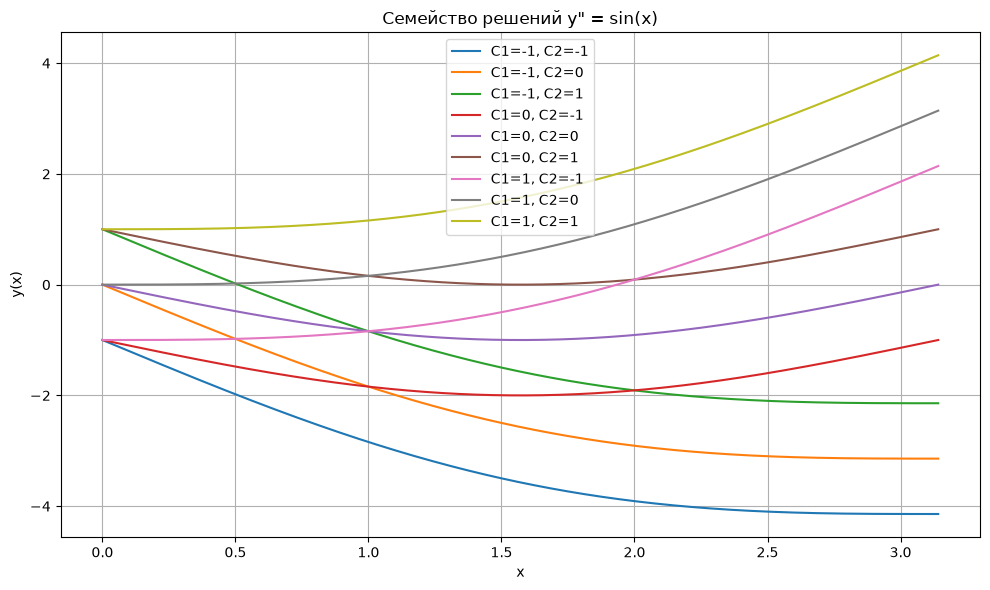

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

a = 0
b = 500

x = np.linspace(a, np.pi, b)

def y(c, C1, C2):
    return -np.sin(x) + C1 * x + C2

plt.figure(figsize=(10,6))

params = [-1, 0, 1]

for C1 in params:
    for C2 in params:
        plt.plot(x, y(x, C1, C2), label=f"C1={C1}, C2={C2}")

plt.xlabel('x')
plt.ylabel('y(x)')
plt.title('Семейство решений y" = sin(x)')
plt.grid()
plt.tight_layout()
plt.legend()
plt.show()

Ну посмотрели и посмотрели

С помощью интерполяционного полинома Лагранжа можно получить формулу второй производной на равномерной сетке ($h_i = h = const$): $$y''(x_i) \approx \frac{y(x_{i-1}) - 2 \cdot y(x_i) + y(x_{i+1})}{h^2}$$

Собственно, подставляем это в наше дифференциальное уравнение $y'' = \sin(x)$ и получаем: 
$$\begin{cases} y'' = \sin(x) \\ y''(x_i) \approx \frac{y(x_{i-1}) - 2 \cdot y(x_i) + y(x_{i+1})}{h^2}  \\ y(x_i) \approx u_i \end{cases} \Longrightarrow \frac{u_{i-1} - 2 \cdot u_i + u_{i+1}}{h^2} = \sin(x_i) \xRightarrow{\cdot h^2} u_{i-1} - 2 \cdot u_i + u_{i+1} = h^2 \cdot \sin(x_i)$$

Мы получили $u_{i-1} - 2 \cdot u_i + u_{i+1} = h^2 \cdot \sin(x_i)$, очевидно, что это соотношение у нас выполняется во всех **внутренних** узлах сетки (которую мы еще не задали...) (внутренние узлы : $i = 1, \dots, N-1$)

Так что давайте зафиксируем сразу тот самый отрезок $[a,b]$, на котором и будем работать с граничной задачей (в коде числа всегда можно будет потом поменять)

А еще сразу введем равномерную сетку: $$x_i = a + i \cdot h, \ \   h = \frac{b - a}{N}, \ \   i = 0, ..., N$$

Тогда получаем: $$\begin{cases}
u_0 - 2 \cdot u_1 + u_2 = h^2 \cdot \sin(x_1) \\
u_1 - 2 \cdot u_2 + u_3 = h^2 \cdot \sin(x_2) \\
u_2 - 2 \cdot u_3 + u_4 = h^2 \cdot \sin(x_3) \\
... \\
u_{N-2} - 2 \cdot u_{N-1} + u_{N} = h^2 \cdot \sin(x_{N-1}) \end{cases}$$

Вот и наш разностный аналог дифференциального уравнения.

Теперь давайте добавим граничные условия, как было сказано выше, это может быть условие одного из трех видов. Для примера рассмотрим условие **Дирихле**.  $$\begin{cases} y(a) = A, \\ y(b) = B \end{cases} \Longrightarrow \begin{cases} u_0 = A \\ u_N = B \end{cases}$$

Тогда получаем: $$\begin{cases}
-2 \cdot u_1 + u_2 = h^2 \cdot \sin(x_1) - A \\
u_1 - 2 \cdot u_2 + u_3 = h^2 \cdot \sin(x_2) \\
u_2 - 2 \cdot u_3 + u_4 = h^2 \cdot \sin(x_3) \\
... \\
u_{N-2} - 2 \cdot u_{N-1} = h^2 \cdot \sin(x_{N-1}) - B \end{cases}$$

Получаем $N-1$ неизвестных для $N-1$ уравнения.  

В матричном виде это $$M \cdot u = d$$

То есть: $$M = \begin{pmatrix}
-2 &  1 &  0 & \cdots &  0 \\
 1 & -2 &  1 & \cdots &  0 \\
 0 &  1 & -2 & \cdots &  0 \\
 \vdots & \vdots & \vdots & \ddots & \vdots \\
 0 &  0 &  0 & 1 & -2
\end{pmatrix} \ , \ 
u = \begin{pmatrix} u_1 \\ u_2 \\ u_3 \\ \vdots \\ u_{N-1} \end{pmatrix} \ , \ 
d = \begin{pmatrix} h^2 \sin(x_1) - A \\ h^2 \sin(x_2) \\ h^2 \sin(x_3) \\ \vdots \\ h^2 \sin(x_{N-1}) - B \end{pmatrix}$$

Ну вот и наша трехдиагональная система линейных алгебраических уравнений.

И решать ее нужно методом трехдиагональной прогонки. Окей. 

Чтобы соответствовать обозначениям лекции включим граничные значения $u_0$ и $u_N$ в вектор неизвестных.

Трехточечное разностное уравнение: $$a_i u_{i-1} - b_i u_i + c_i u_{i+1} = d_i$$

Очевидно: $$\begin{cases} a_i = 1 \\ b_i = 2 \\ c_i = 1 \\ d_i = h^2 \sin(x_i) \end{cases}$$

Рассмотрим прогоночные соотношения: $$u_{n-1} = p_n u_n + q_n , \ n=1,\dots,N$$

$p_n$, $q_n$ - прогоночные коэффициенты: $$\begin{cases} p_{n+1} = \frac{c_n}{b_n - a_n p_n}, \\ q_{n+1} = \frac{a_n q_n - d_n}{b_n - a_n p_n} \end{cases}$$

В прямом прогоне нам надо вычислить именно прогоночные коэффициенты.

Причем $$\begin{cases} p_1 = \frac{c_0}{b_0}, \\ q_1 = - \frac{d_0}{b_0} \end{cases}$$

(Для случая **Дирихле** верно) $$\begin{cases} u_0 = A, \\ u_N = B, \\ b_0 = -1, \\ c_0 = 0, \\ d_0 = A \end{cases} \Longrightarrow \begin{cases} p_1 = 0, \\ q_1 = A \end{cases}$$

Обратный ход прогонки:  
$$\begin{cases} u_N = \frac{a_N q_N - d_N}{b_N - a_N p_N}, \\ u_N = B \end{cases} \Longleftarrow \begin{cases} a_N = 0, \\ b_N = -1, \\ d_N = B \end{cases}$$

Ищем решени в виде прогоночного соотношения (в обратную сторону): $$u_{n-1} = p_n u_n + q_n , \ n=N,\dots,1$$

Тут мы найдем как раз значения $u_i$

Тут стоит сделать паузу, в задаче Неймана может быть такое, что решение может либо не существовать, либо быть неединственным. (Одна из констант никак не определяется, получаем семейство решений, когда нам нужно одно)  

Для этого в случае NN введем нормировку $u_0 = 0$ (дополнительное условие)  

Теперь совместность: $$\int_{a}^{b} y''(x) dx = \int_{a}^{b} \sin{x} dx \Longrightarrow y'(b) - y'(a) = \cos(a) - \cos(b) \Longrightarrow B - A = \cos(a) - \cos(b)$$

Это и есть условие совместности.

Чуть подробнее

$$
\begin{cases}
y''(x)=\sin x,\\
y'(a)=A,\\
y'(b)=B.
\end{cases}
$$

$$
y(x)=-\sin x+C_1x+C_2.
$$

$$
y'(x)=-\cos x+C_1.
$$

Заметим, что константа $C_2$ исчезла при дифференцировании. Следовательно, граничные условия Неймана позволяют определить $C_1$, но не $C_2$.

Нормировка: 

$$
\boxed{y(a)=0.}
$$

В разностной задаче $u_0=0$.

**Условие совместимости**
Мы уже получили до этого

$$
\boxed{B-A=\cos a-\cos b.}
$$


**Вырожденность СЛАУ и дискретная совместимость**

При переходе к разностной схеме проблема неединственности сохраняется.

Если вектор $u=(u_0,\ldots,u_N)^T$ является решением исходной разностной системы с двумя условиями Неймана, то $u+C(1,\ldots,1)^T$ также является решением, поскольку добавление константы не изменяет разности значений функции.

Следовательно, матрица такой СЛАУ вырождена, и для применения метода прогонки необходимо устранить неоднозначность.

Кроме того, при численном решении требуется учитывать **дискретное условие совместимости**.

Используем аппроксимацию граничных производных второго порядка:

$$
\begin{cases}
\dfrac{u_1-u_0}{h}-\dfrac h2\sin a=A,\\[8pt]
\dfrac{u_N-u_{N-1}}h+\dfrac h2\sin b=B.
\end{cases}
$$

Вместе с внутренними разностными уравнениями эти условия приводят к равенству:

$$
B-A=h\left(\frac{\sin x_0}{2}
+\sum_{i=1}^{N-1}\sin x_i
+\frac{\sin x_N}{2}\right).
$$

Правая часть представляет собой составную формулу трапеций для приближённого вычисления интеграла $\int_a^b\sin x\,dx$.

Поскольку результат численного интегрирования в общем случае немного отличается от точного интеграла, непрерывная задача может удовлетворять условию совместимости, а соответствующая дискретная система — нет.

Для устранения этого расхождения введём дискретно согласованное значение правой производной:

$$
\boxed{
B_h=A+h\left(
\frac{\sin x_0}{2}
+\sum_{i=1}^{N-1}\sin x_i
+\frac{\sin x_N}{2}
\right).
}
$$

В нашей реализации вместо левого разностного условия Неймана используется нормировка $u_0=0$, а в правом граничном уравнении применяется значение $B_h$.

При таком построении исключённое левое условие Неймана автоматически выполняется в разностной форме благодаря дискретной совместимости.

При этом формула трапеций имеет второй порядок точности:

$$
B_h-B=O(h^2).
$$

Следовательно, разница между дискретным и исходным граничными значениями стремится к нулю при измельчении сетки.

Таким образом, задача Неймана–Неймана требует специальной обработки по трём причинам:

- решение существует только при выполнении условия совместимости;
- при существовании решение неединственно и требует дополнительной нормировки;
- разностная система должна удовлетворять собственному условию совместимости.

В нашей реализации эти особенности учитываются проверкой граничных данных, введением нормировки $u_0=0$ и использованием дискретно согласованного значения $B_h$. Это позволяет применять метод прогонки и исследовать сходимость численного решения.

In [ ]:
# перейдем к коду!

# отрезок
a = 0
b = np.pi 

# размерность сетки
N = 20

# граничные значения
A = 0
B = 0

# тип граничной задачи
# DD, NN, ND
boundary_type = "DD"

def f(x):
    return np.sin(x)

def make_grid(a, b, N):
    h = (b - a) / N
    x = a + np.arange(N + 1) * h

    return x, h



def progonka(a, b, c, d):
    N = len(d) - 1

    # прогоночные коэффициенты
    p = np.zeros(N + 1)
    q = np.zeros(N + 1)

    # прямой ход
    p[1] = c[0] / b[0]
    q[1] = -d[0] / b[0]

    for n in range(1, N):
        denominator = b[n] - a[n] * p[n]

        p[n + 1] = c[n] / denominator
        q[n + 1] = (a[n] * q[n] - d[n]) / denominator

    # обратный ход
    u = np.zeros(N + 1)

    u[N] = (a[N] * q[N] - d[N]) / (b[N] - a[N] * p[N])

    for n in range(N, 0, -1):
        u[n - 1] = p[n] * u[n] + q[n]

    return u




def build_system(x, h, A, B, boundary_type, f):
    N = len(x) - 1

    a_coef = np.zeros(N + 1)
    b_coef = np.zeros(N + 1)
    c_coef = np.zeros(N + 1)
    d_coef = np.zeros(N + 1)

    fx = np.array([f(t) for t in x])

    # Внутренние узлы
    a_coef[1:N] = 1
    b_coef[1:N] = 2
    c_coef[1:N] = 1
    d_coef[1:N] = h**2 * fx[1:N]

    if boundary_type == "DD":
        # y(a) = A, y(b) = B
        b_coef[0] = -1
        d_coef[0] = A

        b_coef[N] = -1
        d_coef[N] = B

    elif boundary_type == "ND":
        # y'(a) = A
        # аппроксимация второго порядка
        b_coef[0] = 1
        c_coef[0] = 1
        d_coef[0] = h*A + h**2/2 * fx[0]

        # y(b) = B
        b_coef[N] = -1
        d_coef[N] = B

    elif boundary_type == "NN":
        # проверка условия совместимости
        B_required = A + np.cos(x[0]) - np.cos(x[-1])

        if not np.isclose(B, B_required, atol=1e-9, rtol=0):
            raise ValueError(
                f"Несовместимые условия NN: требуется B={B_required:.8f}"
            )

        # дискретная совместимость
        B_h = A + h * (
            0.5*fx[0] + np.sum(fx[1:N]) + 0.5*fx[N]
        )

        # нормировка u_0 = 0
        b_coef[0] = -1
        d_coef[0] = 0

        # правое граничное условие
        a_coef[N] = -1
        b_coef[N] = -1
        d_coef[N] = h*B_h - h**2/2 * fx[N]

    return a_coef, b_coef, c_coef, d_coef


def solve_case(left, right, N, A, B, boundary_type):
    x, h = make_grid(left, right, N)

    coefficients = build_system(
        x, h, A, B, boundary_type, f
    )

    u = progonka(*coefficients)

    return x, u



In [ ]:

def exact_solution(x, a, b, A, B, boundary_type):

    if boundary_type == "DD":
        C1 = (B - A + np.sin(b) - np.sin(a)) / (b - a)
        C2 = A + np.sin(a) - C1*a

    elif boundary_type == "ND":
        C1 = A + np.cos(a)
        C2 = B + np.sin(b) - C1*b

    elif boundary_type == "NN":
        C1 = A + np.cos(a)
        # та же нормировка, что в численном решении
        C2 = np.sin(a) - C1*a

    return -np.sin(x) + C1*x + C2


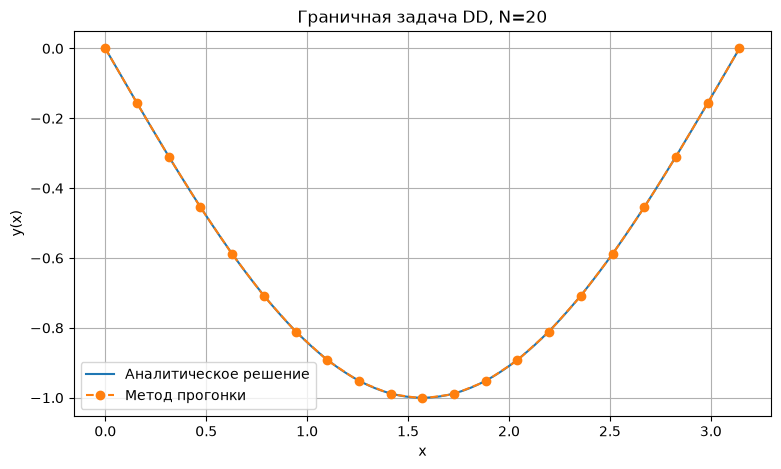

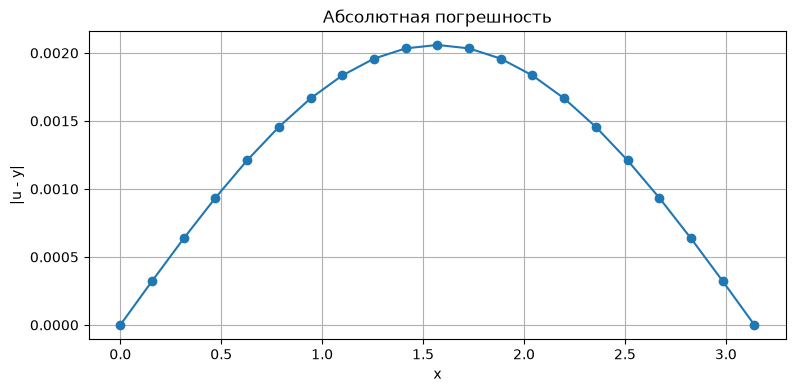

Максимальная погрешность: 2.05870676e-03


In [ ]:

# численное решение
x, u = solve_case(a, b, N, A, B, boundary_type)

# аналитическое решение
x_fine = np.linspace(a, b, 500)
y_fine = exact_solution(x_fine, a, b, A, B, boundary_type)
y_exact = exact_solution(x, a, b, A, B, boundary_type)

# максимальная погрешность
error = np.max(np.abs(u - y_exact))

# график решений
plt.figure(figsize=(9, 5))
plt.plot(x_fine, y_fine, label="Аналитическое решение")
plt.plot(x, u, "o--", label="Метод прогонки")

plt.title(f"Граничная задача {boundary_type}, N={N}")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.legend()
plt.grid(True)
plt.show()

# график абсолютной погрешности
plt.figure(figsize=(9, 4))
plt.plot(x, np.abs(u - y_exact), "o-")

plt.title("Абсолютная погрешность")
plt.xlabel("x")
plt.ylabel("|u - y|")
plt.grid(True)
plt.show()

print(f"Максимальная погрешность: {error:.8e}")



[0, pi], условия DD
    N            h         Ошибка    Порядок
   10     0.314159   8.265417e-03          -
   20     0.157080   2.058707e-03     2.0053
   40     0.078540   5.142005e-04     2.0013
   80     0.039270   1.285204e-04     2.0003
  160     0.019635   3.212824e-05     2.0001

[0, pi], условия ND
    N            h         Ошибка    Порядок
   10     0.314159   2.588117e-02          -
   20     0.157080   6.462299e-03     2.0018
   40     0.078540   1.615076e-03     2.0004
   80     0.039270   4.037379e-04     2.0001
  160     0.019635   1.009325e-04     2.0000

[0, pi], условия NN
    N            h         Ошибка    Порядок
   10     0.314159   2.588117e-02          -
   20     0.157080   6.462299e-03     2.0018
   40     0.078540   1.615076e-03     2.0004
   80     0.039270   4.037379e-04     2.0001
  160     0.019635   1.009325e-04     2.0000


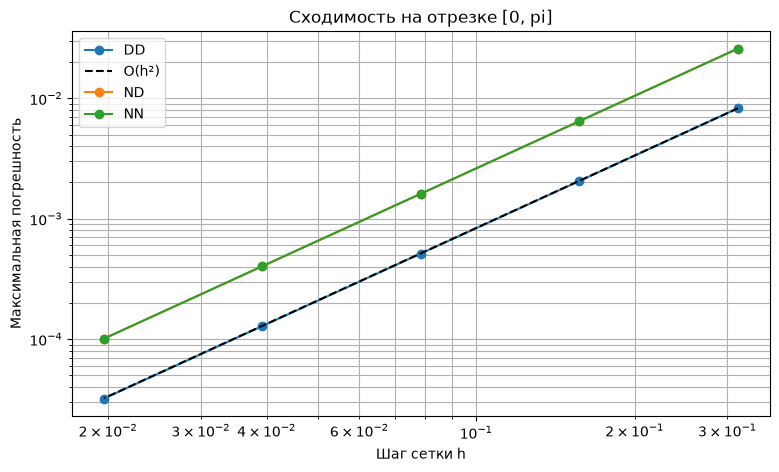


[-pi/2, pi/2], условия DD
    N            h         Ошибка    Порядок
   10     0.314159   1.727613e-03          -
   20     0.157080   4.303047e-04     2.0053
   40     0.078540   1.081908e-04     1.9918
   80     0.039270   2.704146e-05     2.0003
  160     0.019635   6.763330e-06     1.9994

[-pi/2, pi/2], условия ND
    N            h         Ошибка    Порядок
   10     0.314159   1.653083e-02          -
   20     0.157080   4.117414e-03     2.0053
   40     0.078540   1.028401e-03     2.0013
   80     0.039270   2.570408e-04     2.0003
  160     0.019635   6.425648e-05     2.0001

[-pi/2, pi/2], условия NN
    N            h         Ошибка    Порядок
   10     0.314159   1.653083e-02          -
   20     0.157080   4.117414e-03     2.0053
   40     0.078540   1.028401e-03     2.0013
   80     0.039270   2.570408e-04     2.0003
  160     0.019635   6.425648e-05     2.0001


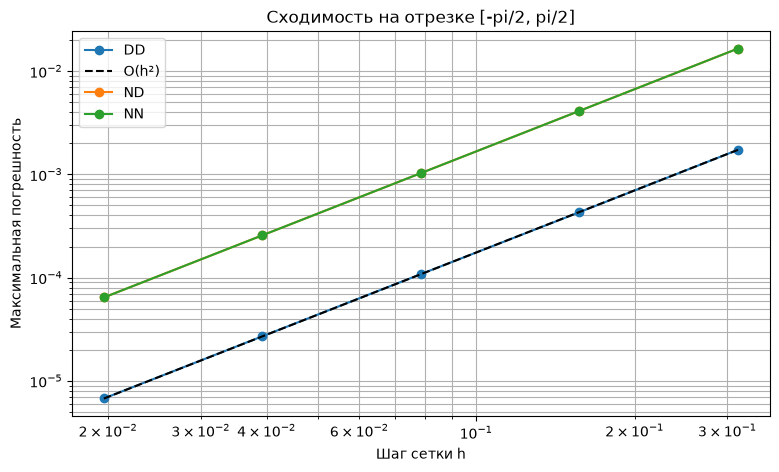

In [ ]:

N_values = [10, 20, 40, 80, 160]

experiments = [
    ("[0, pi]", 0, np.pi, "DD", 0, 0),
    ("[0, pi]", 0, np.pi, "ND", -1, 0),
    ("[0, pi]", 0, np.pi, "NN", -1, 1),

    ("[-pi/2, pi/2]", -np.pi/2, np.pi/2, "DD", 1, -1),
    ("[-pi/2, pi/2]", -np.pi/2, np.pi/2, "ND", 0, -1),
    ("[-pi/2, pi/2]", -np.pi/2, np.pi/2, "NN", 0, 0),
]

for interval in ["[0, pi]", "[-pi/2, pi/2]"]:

    plt.figure(figsize=(9, 5))

    for name, left, right, bc, A_case, B_case in experiments:
        if name != interval:
            continue

        errors = []
        steps = []

        for n in N_values:
            x, u = solve_case(
                left, right, n, A_case, B_case, bc
            )

            y = exact_solution(
                x, left, right, A_case, B_case, bc
            )

            errors.append(np.max(np.abs(u - y)))
            steps.append((right - left) / n)

        errors = np.array(errors)
        steps = np.array(steps)

        # оценка порядка сходимости
        orders = np.log2(errors[:-1] / errors[1:])

        print(f"\n{interval}, условия {bc}")
        print(f"{'N':>5} {'h':>12} {'Ошибка':>14} {'Порядок':>10}")

        for i, n in enumerate(N_values):
            p = "-" if i == 0 else f"{orders[i-1]:.4f}"
            print(f"{n:5d} {steps[i]:12.6f} "
                  f"{errors[i]:14.6e} {p:>10}")

        # график сходимости
        plt.loglog(steps, errors, "o-", label=bc)

        # эталонная линия второго порядка
        if bc == "DD":
            reference = errors[0] * (steps / steps[0])**2
            plt.loglog(
                steps, reference, "k--",
                label="O(h²)"
            )

    plt.title(f"Сходимость на отрезке {interval}")
    plt.xlabel("Шаг сетки h")
    plt.ylabel("Максимальная погрешность")
    plt.legend()
    plt.grid(True, which="both")
    plt.show()


In [6]:

import pandas as pd

summary = []

for interval, left, right, bc, A_case, B_case in experiments:
    errors = []

    for n in [80, 160]:
        x, u = solve_case(left, right, n, A_case, B_case, bc)
        y = exact_solution(x, left, right, A_case, B_case, bc)

        errors.append(np.max(np.abs(u - y)))

    p = np.log2(errors[0] / errors[1])

    summary.append({
        "Отрезок": interval,
        "Условия": bc,
        "Ошибка (N=160)": errors[1],
        "Порядок": p
    })

df = pd.DataFrame(summary)
display(df.round({"Ошибка (N=160)": 8, "Порядок": 4}))


,Отрезок,Условия,Ошибка (N=160),Порядок
0,"[0, pi]",DD,0.000032,2.0001
1,"[0, pi]",ND,0.000101,2.0000
2,"[0, pi]",NN,0.000101,2.0000
3,"[-pi/2, pi/2]",DD,0.000007,1.9994
4,"[-pi/2, pi/2]",ND,0.000064,2.0001
5,"[-pi/2, pi/2]",NN,0.000064,2.0001


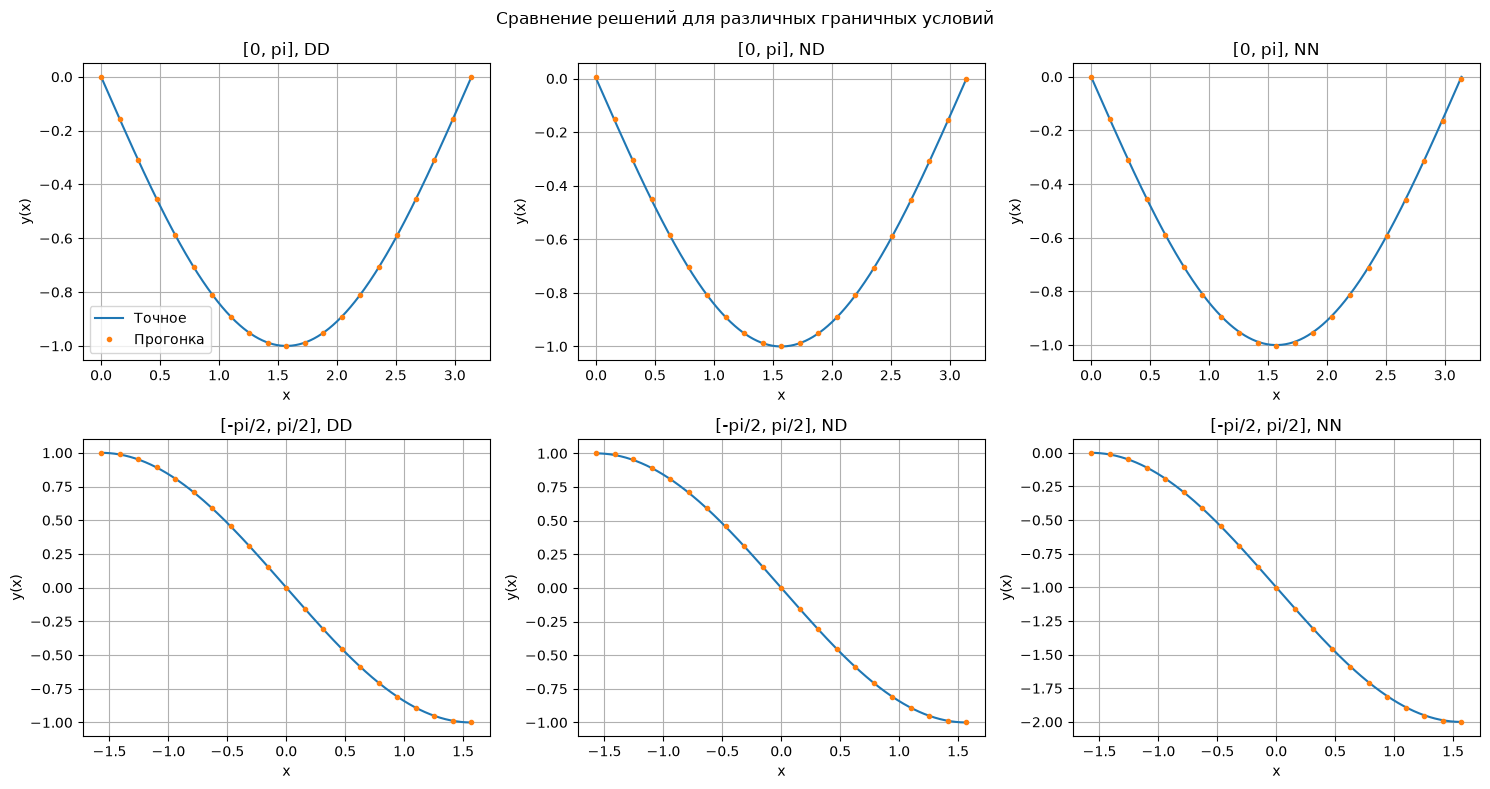

In [7]:

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (interval, left, right, bc, A_case, B_case) in zip(
    axes.flat, experiments
):
    x, u = solve_case(left, right, 20, A_case, B_case, bc)

    x_fine = np.linspace(left, right, 500)
    y_fine = exact_solution(
        x_fine, left, right, A_case, B_case, bc
    )

    ax.plot(x_fine, y_fine, label="Точное")
    ax.plot(x, u, "o", markersize=3, label="Прогонка")

    ax.set_title(f"{interval}, {bc}")
    ax.set_xlabel("x")
    ax.set_ylabel("y(x)")
    ax.grid(True)

axes[0, 0].legend()
fig.suptitle("Сравнение решений для различных граничных условий")
plt.tight_layout()
plt.show()


## Выводы

В ходе лабораторной работы было получено численное решение краевой задачи для дифференциального уравнения \(y''=\sin x\) методом трёхдиагональной прогонки.

Исследованы три типа граничных условий (Дирихле–Дирихле, Нейман–Дирихле и Нейман–Нейман) на двух заданных отрезках.

Сравнение численных решений с аналитическими показало, что при уменьшении шага сетки максимальная погрешность уменьшается. Для рассмотренных разностных схем второго порядка экспериментально получен порядок сходимости \(p\approx2\).

Для всех рассмотренных сочетаний граничных условий экспериментально получен порядок сходимости, близкий ко второму. При уменьшении шага сетки вдвое максимальная погрешность численного решения уменьшается приблизительно в четыре раза. Это согласуется с теоретическим вторым порядком аппроксимации используемой разностной схемы.

Для задачи Неймана–Неймана учитывались условие совместимости граничных данных и необходимость дополнительной нормировки решения. При построении дискретной задачи использовалась поправка к правому граничному условию для обеспечения дискретной совместимости.

Таким образом, численные эксперименты подтверждают ожидаемый второй порядок сходимости использованных схем и показывают влияние способа аппроксимации граничных условий на точность решения.